# CS 6830 - Data Science in Practice 
**Project 6 - Predicting River Baseflow with Multiple Linear Regression** 

Mary Dufie Afrane and Abinash Pant

**Dataset:** RRCA baseflow dataset (Republican River basin). Each row is one river segment in one month, from September 1939 to August 2000.

**Goal:** Use multiple linear regression to predict observed baseflow and to understand how climate, irrigation pumping, location, and time relate to it.


## Columns definitions

* **Baseflow** ([Wikipedia](https://en.wikipedia.org/wiki/Baseflow)) is the part of a river's flow that continues between rain events. It arrives through slow underground paths, so it is what keeps a river running in dry weather. Here it is the target, `Observed`. It is not measured directly: it was estimated by splitting total streamflow into surface water and groundwater (Xu and Valocchi, 2015).
* **Date** the month, stored as days since 01/01/0000. Subtracting 693963 gives a real date.
* **Segment_id** the label of the river segment. It is a name, not a quantity.
* **x, y** the location of the gaging station, which is the instrument that measures the river’s flow. The file does not say what units these map coordinates use, so we use them only to place stations relative to each other.
* **Evapotranspiration** ([Wikipedia](https://en.wikipedia.org/wiki/Evapotranspiration)) is water returned to the air by evaporation and by plants. It is largest in summer. In the water balance it is a loss, so more of it should leave less water for the stream and the aquifer.
* **Precipitation** adds water, but rain has to soak in and travel underground, so its effect on baseflow may be delayed.
* **Irrigation pumping** is groundwater pumped out for crops. In this file it is zero or negative (more negative means more pumped), and it only happens from May to September. Pumping lowers the water table, which should reduce the water flowing into the river.
* **Observed** the baseflow for that segment and month, which is the target we predict.
* **Study area:** the Republican River Basin in Colorado, Kansas and Nebraska. The data comes from the model used by the Republican River Compact Administration (RRCA) to settle water disputes between the states. Xu and Valocchi (2015, *Computers & Geosciences* 85:124-136) used it to correct that model's errors, training on 1941 to 1989 and testing on 1990 to 2000. We use the same style of split below.

We expect evapotranspiration lowers baseflow, precipitation raises it, pumping lowers it, baseflow is lowest in summer, and rivers differ hugely in size.

## Importing Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.stats.stattools as sst
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, MUTED, GRID, SURF = '#0b0b0b', '#898781', '#e1e0d9', '#fcfcfb'
SEQ = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'sans-serif', 'font.size': 11, 'axes.titlesize': 12})

## Load and prepare the data

The raw `Date` column counts days since 01/01/0000. Subtracting 693963 converts it to days since Jan 1, 1900, which we then turn into a real calendar date. Irrigation pumping is stored as zero or negative values, where a more negative value means more groundwater was pumped out near that segment.


In [6]:
df = pd.read_csv('RRCA_baseflow.csv')

In [7]:
df['Date'] = df['Date'] - 693963
df['date'] = pd.to_datetime('1900-01-01') + pd.to_timedelta(df['Date'], unit='D')
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
print(df.shape)
print('Date range:', df['date'].min().date(), 'to', df['date'].max().date())
print('Missing values:', int(df.isnull().sum().sum()))
df.head()

(15591, 11)
Date range: 1939-09-30 to 2000-08-30
Missing values: 0


,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,date,year,month
0,16769,144,1086190,14476800,0.59,18.99,0.0,0.145161,1945-11-30,1945,11
1,16800,144,1086190,14476800,0.97,29.63,0.0,0.445161,1945-12-31,1945,12
2,16828,144,1086190,14476800,1.34,29.63,0.0,1.332203,1946-01-28,1946,1
3,16859,144,1086190,14476800,1.79,29.63,0.0,2.932203,1946-02-28,1946,2
4,16889,144,1086190,14476800,8.23,29.63,0.0,3.728689,1946-03-30,1946,3


In [8]:
df[['Evapotranspiration', 'Precipitation', 'Irrigation_pumping', 'Observed']].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Evapotranspiration,15591.0,2.69,3.17,0.00,0.00,1.04,5.34,12.10
Precipitation,15591.0,14.92,10.51,0.00,0.00,17.49,22.37,40.38
Irrigation_pumping,15591.0,-0.09,0.27,-3.16,-0.01,0.00,0.00,0.00
Observed,15591.0,23.99,56.28,-22.00,1.99,7.70,22.80,747.80


### Data checks
The baseflow unit is not stated in the file; we call it cfs (cubic feet per second), which fits the size of the numbers, but this is an assumption.

**`Segment_id` is not always one station.** A few segment ids appear with two different x/y locations, sometimes in the same month with very different values. We build a `station` id from segment and location so each station is one continuous series.

In [10]:
df['station'] = df.groupby(['Segment_id', 'x', 'y']).ngroup()
n_loc = df.groupby('Segment_id')[['x', 'y']].apply(lambda g: len(g.drop_duplicates()))
print('Segment ids with more than one station location:', list(n_loc[n_loc > 1].index))
print('Stations (segment + location):', df['station'].nunique())
print('Duplicate segment-month rows if location is ignored:', int(df.duplicated(['Segment_id', 'year', 'month']).sum()))
print('Duplicate station-month rows:', int(df.duplicated(['station', 'year', 'month']).sum()))
ex = df[(df['Segment_id'] == 53) & (df['year'] == 1940) & (df['month'] == 10)]
ex[['Segment_id', 'x', 'y', 'date', 'Precipitation', 'Observed']]

Segment ids with more than one station location: [53, 152, 159, 171]
Stations (segment + location): 46
Duplicate segment-month rows if location is ignored: 393
Duplicate station-month rows: 0


,Segment_id,x,y,date,Precipitation,Observed
3196,53,1049230,14666880,1940-10-30,15.43,126.007380
7466,53,991150,14714400,1940-10-30,15.60,20.646721


**zeros that are really missing climate data.** Outside of exact zeros, precipitation is never below 9.9 in any row, yet thousands of rows are exactly 0. Seven stations have zero precipitation and zero evapotranspiration in every month, and two more have long stretches of it. A real basin does not get no rain for decades, so these zeros look like "no data" coded as 0. Left in, they teach the model that a river with low climate values is a particular kind of river. We flag those rows and leave them out of every model that uses climate inputs (`clean` below). Precipitation also changes only about once a year within a station (the same value repeats for many months), so it is closer to an annual figure than a monthly one.

In [12]:
df['clim_missing'] = (df['Precipitation'] == 0).astype(int)
cm = df.groupby('station').agg(segment=('Segment_id', 'first'), rows=('Date', 'size'), rows_zero_precip=('clim_missing', 'sum'))
print(cm[cm['rows_zero_precip'] > 0].to_string())
print('Smallest non-zero precipitation anywhere:', df.loc[df['Precipitation'] > 0, 'Precipitation'].min())
print('Rows with zero precipitation:', int(df['clim_missing'].sum()), 'of', len(df), '| of those, also zero evapotranspiration:', int(((df['clim_missing'] == 1) & (df['Evapotranspiration'] == 0)).sum()))
print('Distinct precipitation values per station-year (clean rows):', round(df[df['clim_missing'] == 0].groupby(['station', 'year'])['Precipitation'].nunique().mean(), 2))
clean = df[df['clim_missing'] == 0].copy()
print('Rows kept in clean:', len(clean), '| stations:', clean['station'].nunique())

         segment  rows  rows_zero_precip
station                                 
1             51   495               495
5             56   653               653
14            98   315               315
22           145   399               399
23           146   459               459
28           152   396               396
34           171   246               246
35           171   447                79
40           189   718               718
42           196   656               656
Smallest non-zero precipitation anywhere: 9.86
Rows with zero precipitation: 4416 of 15591 | of those, also zero evapotranspiration: 4337
Distinct precipitation values per station-year (clean rows): 1.93
Rows kept in clean: 11175 | stations: 37


**negative baseflow.** Baseflow cannot physically be negative, but a few estimates are. We keep them because they are part of the target as given, and show below that removing them changes nothing important.

In [14]:
neg = df[df['Observed'] < 0]
print('Rows with negative baseflow:', len(neg), '| by segment:', neg['Segment_id'].value_counts().to_dict())
print('Rows with exactly zero pumping:', f"{(df['Irrigation_pumping'] == 0).mean():.0%}")
cov = df.groupby('station').agg(first=('year', 'min'), last=('year', 'max'), months=('Date', 'size'))
cov['span_months'] = (df.groupby('station')['Date'].max() - df.groupby('station')['Date'].min()) / 30.4 + 1
cov['share_of_span'] = (cov['months'] / cov['span_months']).clip(upper=1)
print('Stations whose record has gaps (under 90% of months present between first and last):', int((cov['share_of_span'] < 0.9).sum()), 'of', len(cov))

Rows with negative baseflow: 232 | by segment: {178: 222, 176: 10}
Rows with exactly zero pumping: 69%
Stations whose record has gaps (under 90% of months present between first and last): 9 of 46


## Exploratory analysis

First we look at each candidate predictor against observed baseflow. No single input has a clean linear relationship with baseflow when all segments are pooled together.


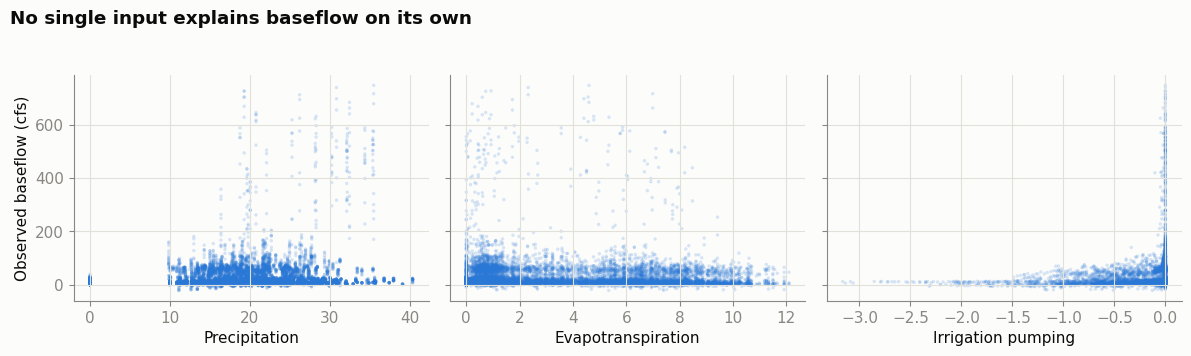

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, col, label in zip(axes,
        ['Precipitation', 'Evapotranspiration', 'Irrigation_pumping'],
        ['Precipitation', 'Evapotranspiration', 'Irrigation pumping']):
    ax.scatter(df[col], df['Observed'], s=6, alpha=0.18, color=BLUE, edgecolors='none')
    ax.set_xlabel(label)
axes[0].set_ylabel('Observed baseflow (cfs)')
fig.suptitle('No single input explains baseflow on its own', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

Baseflow levels differ enormously between segments. The largest segments average hundreds of cfs while the smallest average under 1 cfs. This tells us segment identity will matter a lot for prediction.


In [18]:
seg_stats = df.groupby('Segment_id')['Observed'].agg(['mean', 'std', 'count'])
seg_stats.sort_values('mean', ascending=False).head(8).round(2)

,mean,std,count
Segment_id,,,
256,393.72,185.46,119
239,374.03,175.46,119
194,106.25,53.47,72
157,90.18,12.82,133
188,77.85,21.12,576
205,71.88,44.53,116
53,61.82,54.09,240
130,54.55,10.20,732


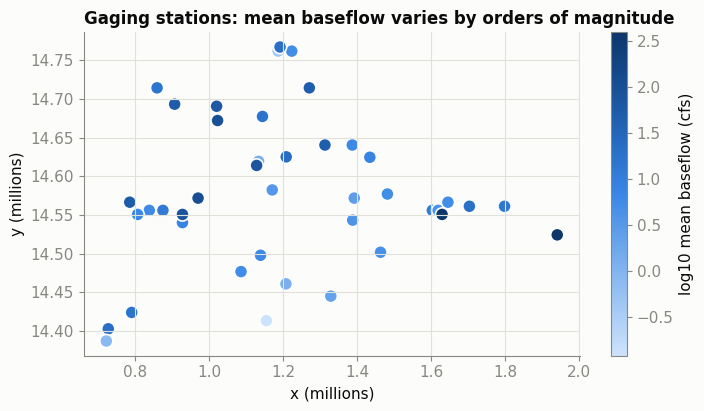

In [19]:
segpos = df.groupby('Segment_id').agg(x=('x', 'mean'), y=('y', 'mean'), bf=('Observed', 'mean')).reset_index()
fig, ax = plt.subplots(figsize=(8, 4.2))
v = np.log10(segpos['bf'].clip(lower=0.1))
cmap = matplotlib.colors.LinearSegmentedColormap.from_list('seq', SEQ)
sc = ax.scatter(segpos['x'] / 1e6, segpos['y'] / 1e6, c=v, s=90, cmap=cmap,
                edgecolors='white', linewidths=1.2)
cb = fig.colorbar(sc, ax=ax)
cb.set_label('log10 mean baseflow (cfs)')
ax.set_xlabel('x (millions)')
ax.set_ylabel('y (millions)')
ax.set_title('Gaging stations: mean baseflow varies by orders of magnitude', loc='left', fontweight='bold')
plt.show()

### Seasonality

Baseflow has a clear yearly cycle. It is lowest in summer, when evapotranspiration is high and pumping happens, and highest in late winter. This pattern is the opposite of evapotranspiration, which fits the background above.

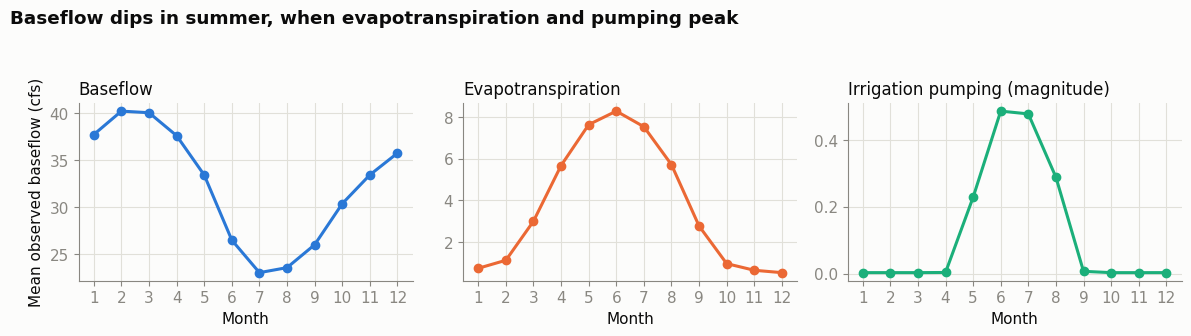

In [21]:
mon = clean.groupby('month').agg(bf=('Observed', 'mean'), et=('Evapotranspiration', 'mean'), pump=('Irrigation_pumping', 'mean'), pr=('Precipitation', 'mean'))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].plot(mon.index, mon['bf'], color=BLUE, lw=2.2, marker='o')
axes[0].set_title('Baseflow', loc='left'); axes[0].set_ylabel('Mean observed baseflow (cfs)')
axes[1].plot(mon.index, mon['et'], color=ORANGE, lw=2.2, marker='o')
axes[1].set_title('Evapotranspiration', loc='left')
axes[2].plot(mon.index, -mon['pump'], color=AQUA, lw=2.2, marker='o')
axes[2].set_title('Irrigation pumping (magnitude)', loc='left')
for ax in axes:
    ax.set_xlabel('Month'); ax.set_xticks(range(1, 13))
fig.suptitle('Baseflow dips in summer, when evapotranspiration and pumping peak', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### Individual stations over time

Four stations of very different size. Each has its own level, its own seasonal swings and its own long term movement, which is why one pooled line cannot fit them all.

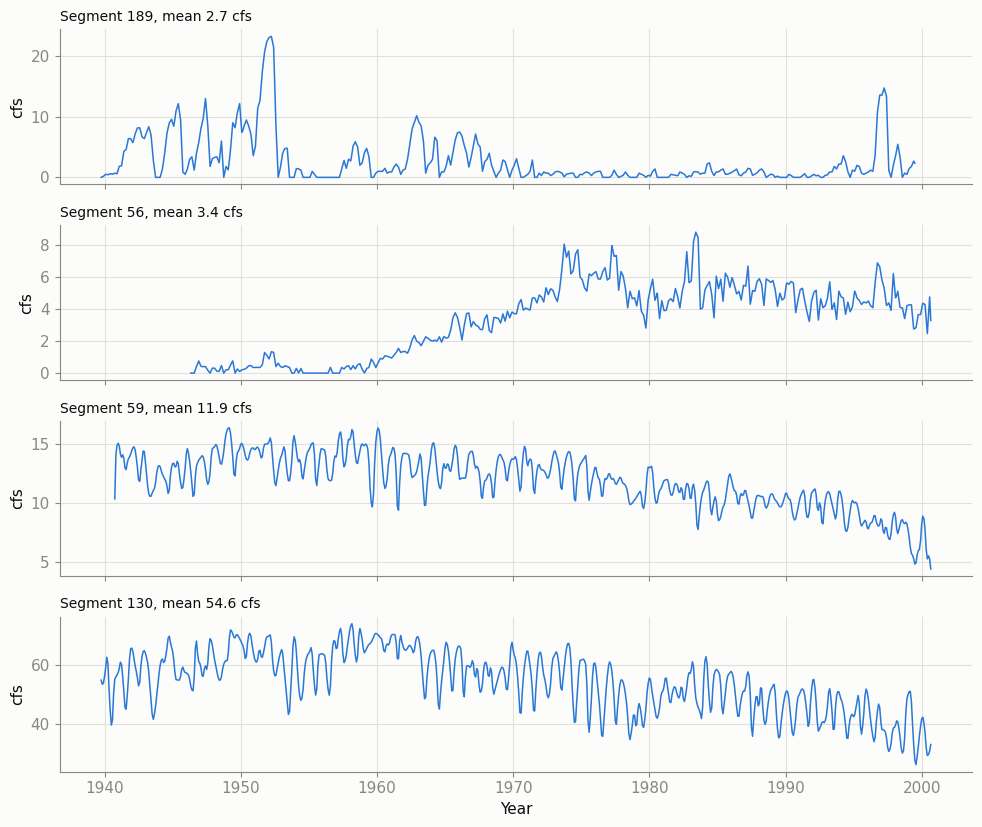

In [23]:
pick = []
for lo, hi in [(0.5, 3), (3, 10), (10, 40), (40, 120)]:
    cand = cov[(cov['share_of_span'] >= 0.9) & (cov['months'] >= 500)].index
    m = df[df['station'].isin(cand)].groupby('station')['Observed'].mean()
    m = m[(m >= lo) & (m < hi)]
    if len(m):
        pick.append(m.index[0])
fig, axes = plt.subplots(len(pick), 1, figsize=(10, 2.1 * len(pick)), sharex=True)
for ax, s in zip(np.atleast_1d(axes), pick):
    g = df[df['station'] == s].sort_values('date')
    ax.plot(g['date'], g['Observed'], color=BLUE, lw=1.1)
    ax.set_ylabel('cfs')
    ax.set_title(f"Segment {int(g['Segment_id'].iloc[0])}, mean {g['Observed'].mean():.1f} cfs", loc='left', fontsize=10)
np.atleast_1d(axes)[-1].set_xlabel('Year')
fig.tight_layout()
plt.show()

### Scatterplots after removing the size of each river

The first scatterplots mixed rivers of every size. Here each station's baseflow is divided by that station's own average (1.0 means a typical month for that river). The clouds are still wide, because month to month variation is large, so the orange line shows the median of 12 equal sized groups along each axis. It tilts the way the background predicted: baseflow rises with precipitation, falls with evapotranspiration and with more pumping, and drifts downward over the years.

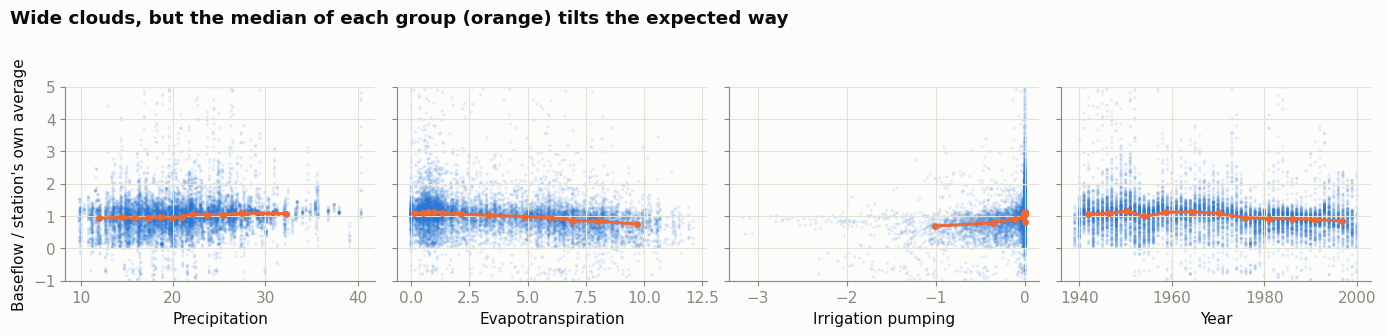

In [25]:
plot = clean[clean.groupby('station')['Observed'].transform('mean') > 0.5].copy()
plot['rel'] = plot['Observed'] / plot.groupby('station')['Observed'].transform('mean')
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, (col, label) in zip(axes, [('Precipitation', 'Precipitation'), ('Evapotranspiration', 'Evapotranspiration'),
                                    ('Irrigation_pumping', 'Irrigation pumping'), ('year', 'Year')]):
    ax.scatter(plot[col], plot['rel'], s=5, alpha=0.12, color=BLUE, edgecolors='none')
    bins = pd.qcut(plot[col].rank(method='first'), 12)
    trend = plot.groupby(bins, observed=True).agg(x=(col, 'mean'), y=('rel', 'median'))
    ax.plot(trend['x'], trend['y'], color=ORANGE, lw=2.2, marker='o', ms=4)
    ax.set_xlabel(label); ax.set_ylim(-1, 5)
axes[0].set_ylabel("Baseflow / station's own average")
fig.suptitle("Wide clouds, but the median of each group (orange) tilts the expected way", x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### Baseflow over time

A naive annual mean over all rows is misleading because the set of gaged stations changes over the years, and several very large ones only appear early in the record. To see a real trend we track the same stations the whole time. We require a station to have at least 90% of all months from 1945 to 1999, so that stations with large gaps are not included, and we drop 2000 because it only runs through August.

Stations with at least 90% of months 1945-1999: 10 | segments: [56, 59, 65, 96, 130, 147, 170, 178, 189, 196]
Mean baseflow of these stations: 22.8 cfs in 1945-49 versus 14.2 cfs in 1995-99 (-38%)
Stations with lower baseflow in 1995-99 than in 1945-49: 6 of 10


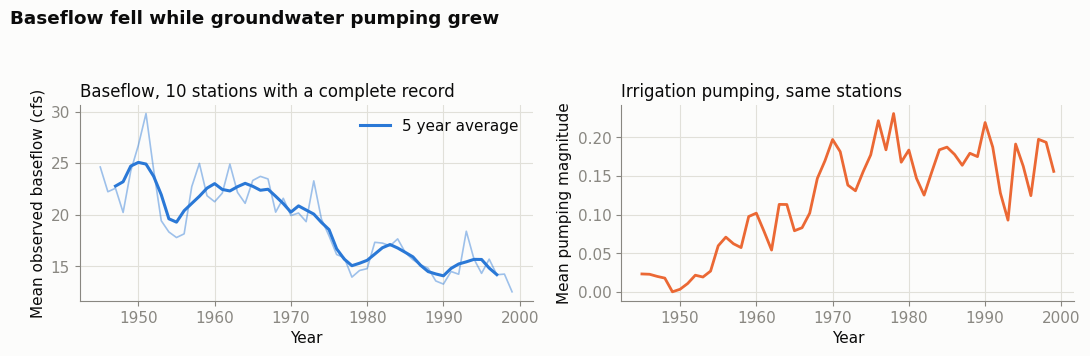

In [27]:
lo_m, hi_m = 1945 * 12 + 1, 1999 * 12 + 12
df['ym'] = df['year'] * 12 + df['month']
share = df[(df['ym'] >= lo_m) & (df['ym'] <= hi_m)].groupby('station').size() / (hi_m - lo_m + 1)
cohort = share[share >= 0.9].index
print('Stations with at least 90% of months 1945-1999:', len(cohort), '| segments:', sorted(int(v) for v in df[df['station'].isin(cohort)]['Segment_id'].unique()))
sub = df[df['station'].isin(cohort) & (df['year'] >= 1945) & (df['year'] <= 1999)]
ann = sub.groupby('year').agg(bf=('Observed', 'mean'), pump=('Irrigation_pumping', 'mean')).reset_index()
ann['bf5'] = ann['bf'].rolling(5, center=True).mean()
early, late = ann.loc[ann['year'] <= 1949, 'bf'].mean(), ann.loc[ann['year'] >= 1995, 'bf'].mean()
print(f'Mean baseflow of these stations: {early:.1f} cfs in 1945-49 versus {late:.1f} cfs in 1995-99 ({late / early - 1:+.0%})')
st_chg = (sub[sub['year'] >= 1995].groupby('station')['Observed'].mean() / sub[sub['year'] <= 1949].groupby('station')['Observed'].mean() - 1)
print('Stations with lower baseflow in 1995-99 than in 1945-49:', int((st_chg < 0).sum()), 'of', len(st_chg))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(ann['year'], ann['bf'], color=BLUE, lw=1.2, alpha=0.45)
axes[0].plot(ann['year'], ann['bf5'], color=BLUE, lw=2.2, label='5 year average')
axes[0].set_ylabel('Mean observed baseflow (cfs)')
axes[0].set_xlabel('Year')
axes[0].set_title(f'Baseflow, {len(cohort)} stations with a complete record', loc='left')
axes[0].legend(frameon=False)
axes[1].plot(ann['year'], -ann['pump'], color=ORANGE, lw=2)
axes[1].set_ylabel('Mean pumping magnitude')
axes[1].set_xlabel('Year')
axes[1].set_title('Irrigation pumping, same stations', loc='left')
fig.suptitle('Baseflow fell while groundwater pumping grew', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

## Regression models

We fit a sequence of multiple linear regression models, each on a random 75/25 train/test split of all rows, and judge them by test set R² and RMSE.

* **Model A:** Date, Evapotranspiration, Precipitation, Irrigation pumping
* **Model B:** Model A plus the station coordinates x and y
* **Model C:** Model A plus Segment id as a one hot encoded categorical variable


In [29]:
features = ['Date', 'Evapotranspiration', 'Precipitation', 'Irrigation_pumping']
RNG = 42
train, test = train_test_split(df, test_size=0.25, random_state=RNG)

def fit_eval(Xtr, Xte, ytr, yte, name):
    m = LinearRegression().fit(Xtr, ytr)
    pred = m.predict(Xte)
    r2 = r2_score(yte, pred)
    rmse = np.sqrt(mean_squared_error(yte, pred))
    print(f'{name}: test R² = {r2:.3f}   test RMSE = {rmse:.2f} cfs')
    return m, pred, r2, rmse

mA, predA, r2A, rmseA = fit_eval(train[features], test[features],
                                 train['Observed'], test['Observed'],
                                 'Model A (climate + pumping + date)')
fB = features + ['x', 'y']
mB, predB, r2B, rmseB = fit_eval(train[fB], test[fB],
                                 train['Observed'], test['Observed'],
                                 'Model B (A + coordinates)      ')

X = pd.get_dummies(df[features + ['Segment_id']], columns=['Segment_id'],
                   drop_first=True, dtype=float)
XtrC, XteC, ytrC, yteC = train_test_split(X, df['Observed'], test_size=0.25, random_state=RNG)
mC, predC, r2C, rmseC = fit_eval(XtrC, XteC, ytrC, yteC,
                                 'Model C (A + segment identity) ')


Model A (climate + pumping + date): test R² = 0.121   test RMSE = 54.59 cfs
Model B (A + coordinates)      : test R² = 0.131   test RMSE = 54.29 cfs
Model C (A + segment identity) : test R² = 0.815   test RMSE = 25.02 cfs


Two cautions about this first pass. A random split puts months from the same river on both sides of the split, so neighboring months (which are very similar) leak between training and test. And the big jump from A to C may come almost entirely from knowing each river's average size, not from the weather. The next section tests both worries.

## A stricter test: predict later years from earlier years

Following the paper by Xu and Valocchi (2015), we train on 1939 to 1989 and test on 1990 to 2000. Can a model fitted on the past predict a decade it has never seen? Everything below uses the `clean` rows (no missing climate values coded as zero) and only stations that appear in both periods.

We compare models against a baseline that ignores the weather completely: predict each station's average baseflow from the training years.

Two extra inputs are built from each station's own history. Rain takes time to reach a river, so we use the average precipitation of the previous 1, 3 and 12 months. Pumping lowers the water table slowly, so we use the average pumping of the previous 12 and 60 month. Rows without enough history are left out, and every model below is scored on the same rows.

Besides the plain additive model (baseflow = sum of effects plus a station level), we try a relative model: the target is baseflow divided by the station's training average. This is still multiple linear regression, but it says the weather changes baseflow by a share of a river's normal flow rather than by a fixed amount, which suits rivers whose size differs by a factor of a thousand.

In [32]:
# History features computed inside each station, on consecutive months only
def history(g):
    g = g.sort_values('ym').set_index('ym')
    full = g[['Precipitation', 'Irrigation_pumping']].reindex(range(g.index.min(), g.index.max() + 1))
    out = pd.DataFrame(index=g.index)
    out['P_lag1'] = full['Precipitation'].shift(1).reindex(g.index)
    out['P_lag3'] = full['Precipitation'].rolling(3, min_periods=3).mean().shift(1).reindex(g.index)
    out['P_lag12'] = full['Precipitation'].rolling(12, min_periods=12).mean().shift(1).reindex(g.index)
    out['pump12'] = full['Irrigation_pumping'].rolling(12, min_periods=12).mean().reindex(g.index)
    out['pump60'] = full['Irrigation_pumping'].rolling(60, min_periods=60).mean().reindex(g.index)
    out['station'] = g['station'].iloc[0]
    return out.reset_index()

hist = pd.concat([history(g) for _, g in df.groupby('station')])
d = df.merge(hist, on=['station', 'ym'], how='left')
d = d[d['clim_missing'] == 0].reset_index(drop=True)
LAGS = ['P_lag1', 'P_lag3', 'P_lag12']
PUMPH = ['pump12', 'pump60']
BASE = ['Date', 'Evapotranspiration', 'Precipitation', 'Irrigation_pumping']
d = d.dropna(subset=LAGS + PUMPH).reset_index(drop=True)
MONTHS = pd.get_dummies(d['month'], prefix='m', drop_first=True, dtype=float)
for c in MONTHS.columns:
    d[c] = MONTHS[c]
MCOLS = list(MONTHS.columns)

TRAIN_END = 1989
train_mask = d['year'] <= TRAIN_END
test_mask = (d['year'] > TRAIN_END) & d['station'].isin(d.loc[train_mask, 'station'].unique())
print(f'Rows available: {len(d)} | training (to {TRAIN_END}): {int(train_mask.sum())} | test (1990 and later): {int(test_mask.sum())}')

rs = np.random.RandomState(42)
rand_train = pd.Series(rs.rand(len(d)) < 0.75, index=d.index)
rand_test = (~rand_train) & d['station'].isin(d.loc[rand_train, 'station'].unique())

Rows available: 7909 | training (to 1989): 6490 | test (1990 and later): 1418


In [33]:
def score(y_true, pred):
    return r2_score(y_true, pred), float(np.sqrt(mean_squared_error(y_true, pred)))

def additive(cols, tr, te, with_station=True):
    X = d[cols].copy()
    if with_station:
        X = pd.concat([X, pd.get_dummies(d['station'], prefix='st', drop_first=True, dtype=float)], axis=1)
    m = LinearRegression().fit(X[tr], d.loc[tr, 'Observed'])
    return m.predict(X[te])

def relative(cols, tr, te, return_model=False):
    # baseflow as a share of the station's own training average
    level = d.loc[tr].groupby('station')['Observed'].mean()
    sc = d['station'].map(level)
    fit = tr & (sc.abs() > 0.5)   # tiny stations would give unstable ratios
    m = LinearRegression().fit(d.loc[fit, cols], (d['Observed'] / sc)[fit])
    pred = m.predict(d.loc[te, cols]) * sc[te]
    return (pred, m) if return_model else pred

def baseline(tr, te):
    level = d.loc[tr].groupby('station')['Observed'].mean()
    return d.loc[te, 'station'].map(level).values

models = {
    'Station average only (no weather)': lambda tr, te: baseline(tr, te),
    'A: pooled, weather + pumping + date': lambda tr, te: additive(BASE, tr, te, with_station=False),
    'C: A + station level': lambda tr, te: additive(BASE, tr, te),
    'C + month of year': lambda tr, te: additive(BASE + MCOLS, tr, te),
    'C + rain and pumping history': lambda tr, te: additive(BASE + LAGS + PUMPH, tr, te),
    'Relative: A, as share of station average': lambda tr, te: relative(BASE, tr, te),
    'Relative: date only': lambda tr, te: relative(['Date'], tr, te),
    'Relative: weather and pumping, no date': lambda tr, te: relative(['Evapotranspiration', 'Precipitation', 'Irrigation_pumping'], tr, te),
    'Relative + month of year': lambda tr, te: relative(BASE + MCOLS, tr, te),
    'Relative + rain and pumping history': lambda tr, te: relative(BASE + LAGS + PUMPH, tr, te),
}

rows = []
for name, f in models.items():
    r2_rand, _ = score(d.loc[rand_test, 'Observed'], f(rand_train, rand_test))
    r2_time, rmse_time = score(d.loc[test_mask, 'Observed'], f(train_mask, test_mask))
    rows.append({'Model': name, 'R² random split': round(r2_rand, 3), 'R² 1990 and later': round(r2_time, 3), 'RMSE 1990 and later (cfs)': round(rmse_time, 1)})
results = pd.DataFrame(rows)
results

,Model,R² random split,R² 1990 and later,RMSE 1990 and later (cfs)
0,Station average only (no weather),0.777,0.611,10.7
1,"A: pooled, weather + pumping + date",0.095,-1.050,24.6
2,C: A + station level,0.785,0.697,9.5
3,C + month of year,0.793,0.675,9.8
4,C + rain and pumping history,0.786,0.721,9.1
5,"Relative: A, as share of station average",0.725,0.778,8.1
6,Relative: date only,0.749,0.740,8.8
7,"Relative: weather and pumping, no date",0.771,0.669,9.9
8,Relative + month of year,0.800,0.750,8.6
9,Relative + rain and pumping history,0.704,0.776,8.1


**Reading the table.**

1. The station average alone scores about 0.78 on the random split, because most of the variation in this dataset is simply "this river is big and that one is small". Adding weather to the station level barely helps there (0.785).
2. On the future test the baseline falls to 0.61, and the relative model reaches 0.78 (RMSE 8.1 versus 10.7 cfs). Most of that gain is the downward drift: a model with only the date as input reaches 0.74, while one with weather and pumping but no date reaches 0.67.
3. The relative model is actually worse than the plain station average on the random split (0.73 versus 0.78), so its benefit appears only when predicting later years.
4. Month of year helps on the random split but hurts on the future test, a sign that the seasonal pattern itself changed over time (pumping is a summer activity and it grew).
5. Rain and pumping history gives a small gain for the additive model (0.70 to 0.72) and none for the relative model.

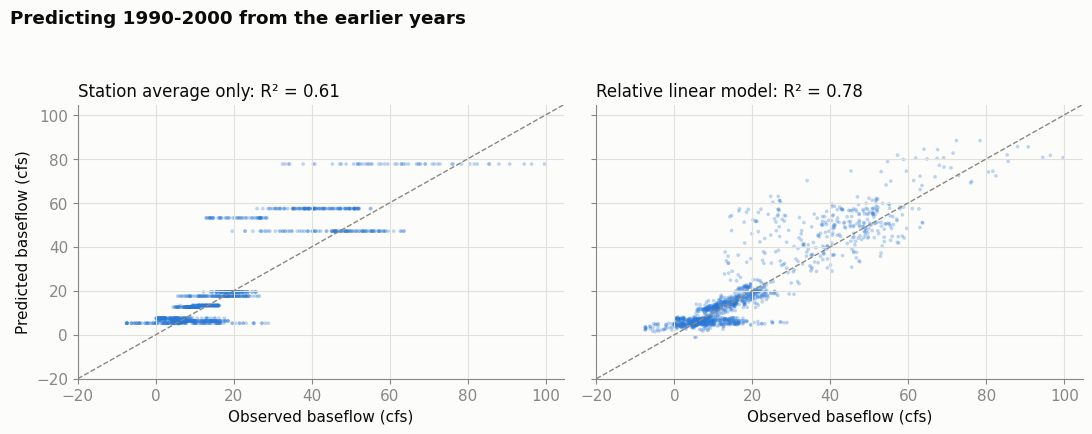

In [35]:
# Predicted versus observed for the 1990-2000 test period: baseline vs relative model
pred_base = baseline(train_mask, test_mask)
pred_rel = relative(BASE, train_mask, test_mask)
yt = d.loc[test_mask, 'Observed']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, sharex=True)
lims = [-20, max(yt.max(), pred_rel.max()) * 1.05]
for ax, p, ttl in [(axes[0], pred_base, f'Station average only: R² = {r2_score(yt, pred_base):.2f}'),
                   (axes[1], pred_rel, f'Relative linear model: R² = {r2_score(yt, pred_rel):.2f}')]:
    ax.scatter(yt, p, s=7, alpha=0.3, color=BLUE, edgecolors='none')
    ax.plot(lims, lims, color=MUTED, lw=1, ls='--')
    ax.set_xlabel('Observed baseflow (cfs)'); ax.set_title(ttl, loc='left')
    ax.set_xlim(lims); ax.set_ylim(lims)
axes[0].set_ylabel('Predicted baseflow (cfs)')
fig.suptitle('Predicting 1990-2000 from the earlier years', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

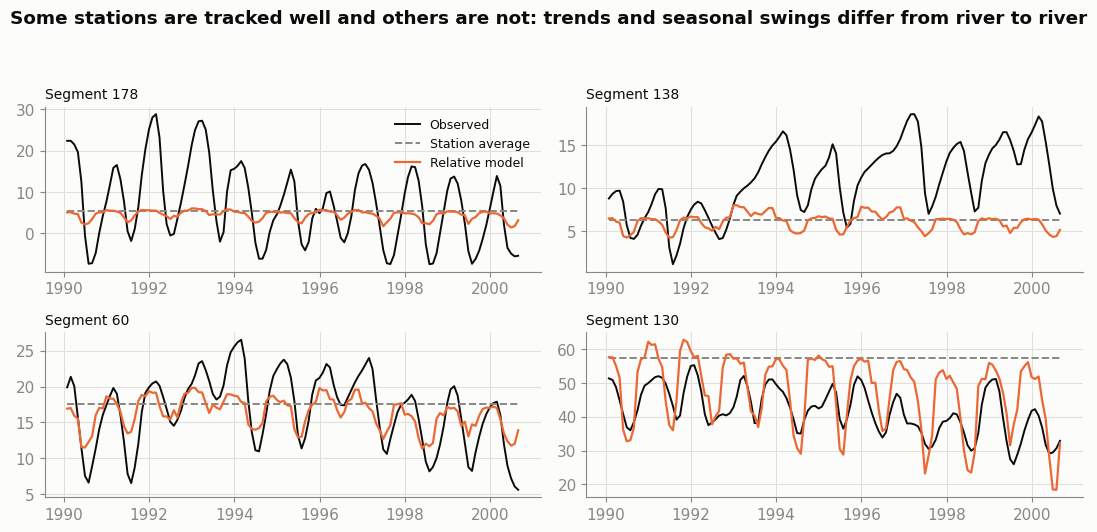

In [36]:
# Four test stations through time: observed versus the two predictions
te_d = d[test_mask].copy()
te_d['pred_base'] = pred_base
te_d['pred_rel'] = pred_rel
cnt = te_d.groupby('station').size()
cand = te_d[te_d['station'].isin(cnt[cnt >= 80].index)].groupby('station')['Observed'].mean().sort_values()
show = [cand.index[int(q * (len(cand) - 1))] for q in (0.15, 0.4, 0.65, 0.9)]
fig, axes = plt.subplots(2, 2, figsize=(11, 5.4))
for ax, s in zip(axes.ravel(), show):
    g = te_d[te_d['station'] == s].sort_values('date')
    ax.plot(g['date'], g['Observed'], color=INK, lw=1.4, label='Observed')
    ax.plot(g['date'], g['pred_base'], color=MUTED, lw=1.4, ls='--', label='Station average')
    ax.plot(g['date'], g['pred_rel'], color=ORANGE, lw=1.6, label='Relative model')
    ax.set_title(f"Segment {int(g['Segment_id'].iloc[0])}", loc='left', fontsize=10)
axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle('Some stations are tracked well and others are not: trends and seasonal swings differ from river to river', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### What the relative model says about each input

We refit the relative model on the training years and read its coefficients as "percentage points of a river's normal flow". Because neighboring months from one river are strongly related, ordinary p values are too optimistic. We therefore report p values that allow errors to be correlated within a station (cluster robust, clustered by station), which is the more honest version.

In [38]:
level = d.loc[train_mask].groupby('station')['Observed'].mean()
sc = d['station'].map(level)
fit = train_mask & (sc.abs() > 0.5)
Xr = sm.add_constant(d.loc[fit, BASE])
yr = (d['Observed'] / sc)[fit]
ols_rel = sm.OLS(yr, Xr).fit(cov_type='cluster', cov_kwds={'groups': d.loc[fit, 'station']})
ols_plain = sm.OLS(yr, Xr).fit()
tab = pd.DataFrame({'coef': ols_rel.params, 'p (ordinary)': ols_plain.pvalues, 'p (clustered by station)': ols_rel.pvalues})
tab['meaning'] = ''
tab.loc['Date', 'meaning'] = f"{ols_rel.params['Date'] * 365.25 * 100:+.1f} points of normal flow per year"
tab.loc['Evapotranspiration', 'meaning'] = f"{ols_rel.params['Evapotranspiration'] * 100:+.1f} points per unit of ET"
tab.loc['Precipitation', 'meaning'] = f"{ols_rel.params['Precipitation'] * 100:+.1f} points per unit of precipitation"
tab.loc['Irrigation_pumping', 'meaning'] = f"{ols_rel.params['Irrigation_pumping'] * 100:+.1f} points per unit of pumping (positive: more pumping, less flow)"
print('Relative model fitted on 1939-1989, stations:', fit.sum(), 'rows from', d.loc[fit, 'station'].nunique(), 'stations')
tab.round(4)

Relative model fitted on 1939-1989, stations: 6490 rows from 32 stations


,coef,p (ordinary),p (clustered by station),meaning
const,1.1386,0.0,0.0000,
Date,-0.0000,0.0,0.0906,-0.4 points of normal flow per year
Evapotranspiration,-0.0281,0.0,0.0000,-2.8 points per unit of ET
Precipitation,0.0154,0.0,0.0017,+1.5 points per unit of precipitation
Irrigation_pumping,0.2502,0.0,0.2807,+25.0 points per unit of pumping (positive: mo...


In [39]:
# Can the weather alone predict a station the model has never seen? Leave whole stations out.
rows = []
Xa, ya = d[BASE], d['Observed']
for k, (tri, tei) in enumerate(GroupKFold(5).split(Xa, ya, d['station'])):
    m = LinearRegression().fit(Xa.iloc[tri], ya.iloc[tri])
    rows.append(r2_score(ya.iloc[tei], m.predict(Xa.iloc[tei])))
print('Model A, each fold predicts stations it never saw. R² per fold:', np.round(rows, 2), '| mean:', round(float(np.mean(rows)), 2))

Model A, each fold predicts stations it never saw. R² per fold: [ 0.08 -1.35 -1.3  -0.47  0.09] | mean: -0.59


**Unseen rivers.** For a river the model has never seen, the weather inputs are not enough: R² is near zero or negative. A new river's size is simply not in these columns. The models above work because they learned each river's typical level from its own history.

### Do the data cleaning choices matter?

We repeat the main future-test comparison under four versions of the data to check that the conclusions do not hinge on how we handled the odd rows.

In [41]:
def future_test(data, label):
    data = data.reset_index(drop=True)
    tr = data['year'] <= TRAIN_END
    te = (data['year'] > TRAIN_END) & data['station'].isin(data.loc[tr, 'station'].unique())
    level = data.loc[tr].groupby('station')['Observed'].mean()
    sc_ = data['station'].map(level)
    fit_ = tr & (sc_.abs() > 0.5)
    m = LinearRegression().fit(data.loc[fit_, BASE], (data['Observed'] / sc_)[fit_])
    p_rel = m.predict(data.loc[te, BASE]) * sc_[te]
    p_base = data.loc[te, 'station'].map(level)
    return {'Version of the data': label, 'rows': len(data),
            'R² station average': round(r2_score(data.loc[te, 'Observed'], p_base), 3),
            'R² relative model': round(r2_score(data.loc[te, 'Observed'], p_rel), 3)}

versions = [(df, 'All rows'), (df[df['clim_missing'] == 0], 'Drop zero-precipitation rows (our choice)'),
            (df[df['Observed'] >= 0], 'Drop negative baseflow'),
            (df[(df['clim_missing'] == 0) & (df['Observed'] >= 0)], 'Drop both')]
pd.DataFrame([future_test(v, l) for v, l in versions])

,Version of the data,rows,R² station average,R² relative model
0,All rows,15591,0.650,0.797
1,Drop zero-precipitation rows (our choice),11175,0.620,0.807
2,Drop negative baseflow,15359,0.653,0.802
3,Drop both,10943,0.618,0.800


## Per station regressions

A single pooled model forces one climate response on every river. Fitting a separate regression to each station (on the clean rows, keeping stations with at least 30 months of data, and dropping any predictor that is constant within a station, such as pumping where no pumping occurred) lets each river have its own behavior.

In [43]:
rows = []
for s, g in clean.groupby('station'):
    if len(g) < 30:
        continue
    cols = [c for c in BASE if g[c].nunique() > 1]
    r = sm.OLS(g['Observed'], sm.add_constant(g[cols])).fit()
    row = {'station': s, 'Segment_id': int(g['Segment_id'].iloc[0]), 'n': len(g), 'r2': r.rsquared,
           'mean_bf': g['Observed'].mean(), 'dw': sst.durbin_watson(r.resid)}
    for c in cols:
        row[f'coef_{c}'] = r.params[c]
        row[f'p_{c}'] = r.pvalues[c]
    rows.append(row)
per = pd.DataFrame(rows)
print('Stations modeled:', len(per))
print('R² quartiles:', per['r2'].quantile([0.25, 0.5, 0.75]).round(3).to_dict())
sig_pr = ((per['coef_Precipitation'] > 0) & (per['p_Precipitation'] < 0.05)).mean()
sig_et = ((per['coef_Evapotranspiration'] < 0) & (per['p_Evapotranspiration'] < 0.05)).mean()
sig_dt = ((per['coef_Date'] < 0) & (per['p_Date'] < 0.05)).mean()
print(f'Share with significant positive precipitation effect: {sig_pr:.0%}')
print(f'Share with significant negative evapotranspiration effect: {sig_et:.0%}')
print(f'Share with significant negative time trend: {sig_dt:.0%}')
pumped = per[per['coef_Irrigation_pumping'].notna()]
sig_pu = ((pumped['coef_Irrigation_pumping'] > 0) & (pumped['p_Irrigation_pumping'] < 0.05)).mean()
print(f'Pumped stations: {len(pumped)}; share with significant pumping effect in the expected direction: {sig_pu:.0%}')
print(f"Median Durbin-Watson statistic: {per['dw'].median():.2f}  (2 means independent errors; values near 0 mean neighboring months are strongly related)")

Stations modeled: 36
R² quartiles: {0.25: 0.28, 0.5: 0.452, 0.75: 0.623}
Share with significant positive precipitation effect: 81%
Share with significant negative evapotranspiration effect: 69%
Share with significant negative time trend: 42%
Pumped stations: 33; share with significant pumping effect in the expected direction: 67%
Median Durbin-Watson statistic: 0.33  (2 means independent errors; values near 0 mean neighboring months are strongly related)


Fitting each station separately fixes the size problem, so the expected signs show up in most stations. These shares are still counts of "significant" results from tests that assume independent months. The Durbin-Watson values show that they are not independent, so treat the shares as a rough guide to direction, not as proof.

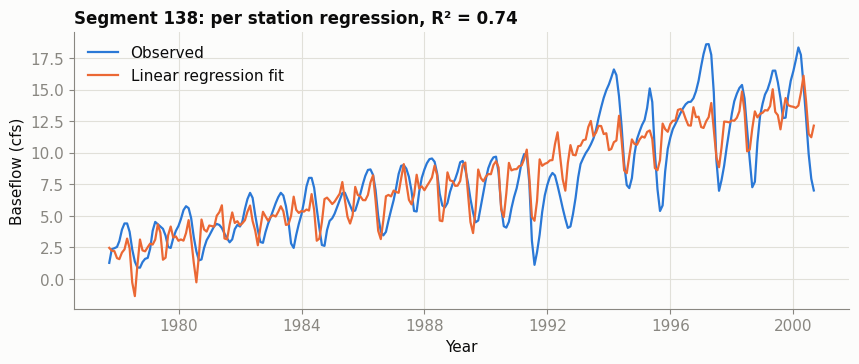

In [45]:
best = per.sort_values('r2', ascending=False).iloc[0]
g = clean[clean['station'] == int(best['station'])].sort_values('date')
cols = [c for c in BASE if g[c].nunique() > 1]
r = sm.OLS(g['Observed'], sm.add_constant(g[cols])).fit()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(g['date'], g['Observed'], color=BLUE, lw=1.6, label='Observed')
ax.plot(g['date'], r.fittedvalues, color=ORANGE, lw=1.6, label='Linear regression fit')
ax.set_ylabel('Baseflow (cfs)')
ax.set_xlabel('Year')
ax.legend(frameon=False)
ax.set_title(f"Segment {int(best['Segment_id'])}: per station regression, R² = {best['r2']:.2f}", loc='left', fontweight='bold')
plt.show()

## What we tried that did not help

* **Segment id as the station.** Four segment ids contain two stations each (393 duplicate segment-month rows). Using a station id instead changes little in the headline scores but makes each series continuous.
* **Dropping the zero-precipitation rows, or the negative baseflow rows.** The relative model's future test R² stays between 0.80 and 0.81 in every version, so the conclusions do not depend on these choices.
* **Station coordinates (Model B).** Test R² rose from 0.12 to only 0.13. Location only matters through which station a row belongs to, and the station level already carries that.
* **Month of year.** Better on a random split, worse when predicting 1990 to 2000.
* **Rain and pumping history.** A small gain for the additive model, none for the relative model.
* **Weather alone for a station the model has not seen.** R² near zero or negative, so a new river's size cannot be recovered from these columns.

## Conclusions

* The weather, pumping and date alone explain little of pooled baseflow (test R² about 0.12 on a random split) because the stations sit on completely different flow scales.
* Most of the apparent skill of Model C (test R² about 0.82) comes from knowing each river's typical level: predicting only each station's average already scores about 0.78 on a comparable random split.
* Predicting 1990 to 2000 from 1939 to 1989 is the honest test. A baseline of each station's average scores R² 0.61. A relative linear model (baseflow as a share of the station's normal flow, using date, evapotranspiration, precipitation and pumping) scores 0.78 and cuts RMSE from 10.7 to 8.1 cfs. About three quarters of that improvement is the downward drift over time (date alone: 0.74).
* Evapotranspiration lowers baseflow (about 3 points of a river's normal flow per unit, clustered p below 0.001) and precipitation raises it (about 1.5 points per unit, clustered p 0.002). Within stations the same signs hold in most rivers (precipitation 81%, evapotranspiration 69%).
* Pumping has the expected sign (more pumping, less baseflow) and the 10 stations with complete records show baseflow falling from about 23 cfs in 1945 to 1949 to about 14 cfs in 1995 to 1999 while pumping grew from near zero. But once errors are allowed to be correlated within a station, the pumping coefficient is not statistically distinguishable from zero (clustered p about 0.28), because pumping and the date rise together. We can say the two moved together, not that this data isolates the effect of pumping.
* Linear regression is a reasonable first model here, but it cannot capture seasonal swings that change over time or the delayed response of groundwater, and it cannot predict a river it has never seen. Natural next steps are nonlinear models such as the random forests and support vector regression used by Xu and Valocchi (2015), and seasonal effects that are allowed to change over the years.